# Rotation sandbox 2

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
# Set parameters for all plots in notebook
file = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_11_1.0cmHL/2rod_14oclock_1e7_85bins_1.0cmHL.csv"
z_slice = 25
norm_point = (0.0, 0.3)
bins = 85
dose_grid_half = 1.0
lattice = dose_grid_half*2/bins
source_transZ = -0.5
source_plane = cm_to_voxel(np.array(source_transZ), bins, dose_grid_half*2/bins)
applicator_rad = 0.3

source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-1.0, 1.0)
rngY = (-1.0, 1.0)

In [4]:
norm_energy, __ = extract_norm_energy(file, source_plane, 2, norm_point, bins, lattice)

In [5]:
X, Y, energy, __ = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy, zero_source=True, std_dev=False)

In [6]:
def twoD_rot(theta: float) -> np.ndarray:
    return np.array([[np.cos(theta), -1*np.sin(theta)], [np.sin(theta), np.cos(theta)]])

In [7]:
angle = pi/4
test_rot = twoD_rot(angle)
print(test_rot)

[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


In [8]:
rotated_energy = np.zeros(np.shape(energy))
flag1 = True
flag2 = True
flag3 = True
flag4 = True

hold_voxels_x = set()
hold_voxels_y = set()

for x in np.arange(0, np.shape(X)[0]):
    for y in np.arange(0, np.shape(Y)[0]):
        vector = np.array([X[x], Y[y]])
        
        if np.linalg.norm(vector) <= dose_grid_half:
            eng = energy[x][y]
    
            vox_vector = cm_to_voxel(vector, bins, lattice)
            if vox_vector[0] != x:
                flag3 = False
                hold_voxels_x.add(x)
                #print(str(vox_vector) + " " + str(x) + " " + str(y))
            if vox_vector[1] != y:
                flag3 = False
                hold_voxels_y.add(y)
                
            rot_vector = test_rot @ vector
            if not np.array_equal(rot_vector, vector):
                flag1 = False
    
            vox_rot_vector = cm_to_voxel(rot_vector, bins, lattice)
            if vox_rot_vector[0] != x or vox_rot_vector[1] != y:
                flag2 = False
    
            if vox_rot_vector[0] != vox_vector[0] or vox_rot_vector[1] != vox_vector[1]:
                flag4 = False
    
            rotated_energy[vox_rot_vector[0]][vox_rot_vector[1]] = eng

print(flag1) # True --> rotated vector equal to original vector for angle = 0
print(flag2) # False --> indicates that cm --> voxel mapping is many-to-one for some inputs
print(flag3) # False --> cm_to_voxel does not have expected behavior before rotation...
print(flag4) # True ---> ...but voxel obtained before and after 0 rad rotation is the same, as expected

print(hold_voxels_x)
print(hold_voxels_y)

False
False
True
False
set()
set()


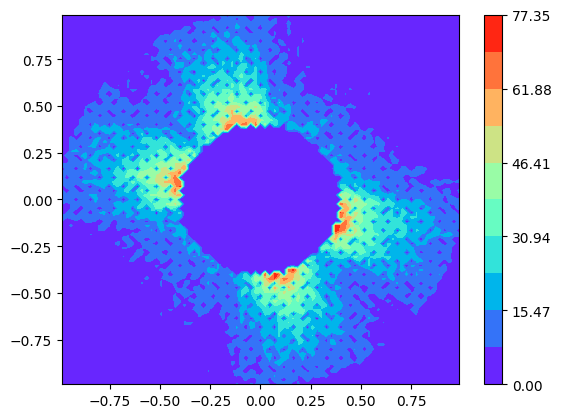

In [9]:
fig, ax = plt.subplots()
contour = ax.contourf(X, Y, rotated_energy, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig.colorbar(contour)

### Stabilizing cm_to_voxel

In [10]:
voxel = np.arange(0, bins)
store_old_voxels = []
store_new_voxels = []
for vox in voxel:
    #print(vox)
    cm = voxel_to_cm(np.array([vox]), bins, lattice)
    #print(cm)
    new_vox = cm_to_voxel(cm, bins, lattice)
    #print(new_vox)
    if new_vox[0] != vox:
        #print("FALSE")
        store_old_voxels.append(vox)
        store_new_voxels.append(new_vox[0])
    #print("################")

print(store_old_voxels)
print(store_new_voxels)

[]
[]


### Extracting allowed range for arbitrary rotations

In [11]:
arb_theta = pi/1.5
arb_rot = twoD_rot(arb_theta)

In [12]:
rotation = np.zeros(np.shape(energy))

holding = set()
test = []

for i in np.arange(0, np.shape(X)[0]):
    for j in np.arange(0, np.shape(Y)[0]):
        vector = np.array([X[i], Y[j]])

        if np.linalg.norm(vector) <= dose_grid_half:
            height = energy[i][j]

            rotated_vec = arb_rot @ vector

            rotated_voxel = cm_to_voxel(rotated_vec, bins, lattice)

            rotation[rotated_voxel[0]][rotated_voxel[1]] = height

            test_tuple = (rotated_voxel[0], rotated_voxel[1])
            if test_tuple in holding:
                test.append(test_tuple)
                
                result = int(bins/2) + rotated_vec/lattice
                round = result.round()
                other_round = int(bins/2) + (rotated_vec/lattice).round()
                #print(result, round, other_round)
                #print(rotated_vec, test_tuple)

            holding.add(test_tuple)

#print(test) # test is not empty, indicating that multiple rotated vectors are mapped to the same rotated voxels - results in "empty" rotated voxels
#print(len(test)) # note that the number of "missing" voxels gets lower as rotation angle approaches pi/2 (or 0, pi, etc.)

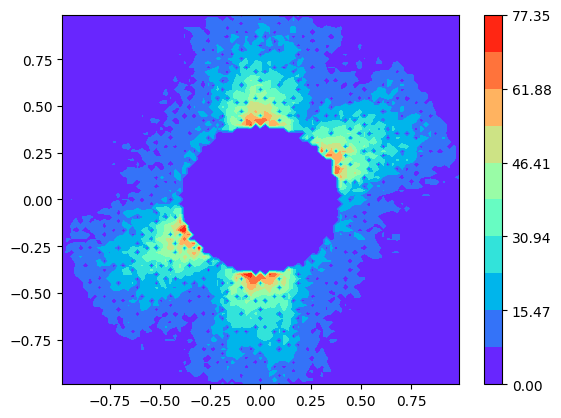

In [13]:
fig1, ax1 = plt.subplots()
contour1 = ax1.contourf(X, Y, rotation, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar1 = fig1.colorbar(contour1)

In [14]:
print(np.arange(0, np.shape(X)[0]))

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84]


In [15]:
# Generate test vector
hold = []
for k in X:
    vec = np.array([k, k])
    hold.append(vec)

#print(hold)

rotated_hold = []
for vector in hold:
    rot = arb_rot @ vector
    rotated_hold.append(rot)

#print(rotated_hold)

In [16]:
test_transform = cm_to_voxel(rotated_hold[0], bins, lattice)
print(test_transform)

[99 27]
